# **Notebook 1: Data Audit and Source Selection**

**Overall Notebook Description:** Audit data quality and compare three candidate sources to guide source selection.

This notebook compares three candidates: the local original CIC-IDS2017 labeled flows, the CNS2022 corrected CIC-IDS2017 release, and UNSW-NB15. The first two receive a complete Tuesday-only raw-record audit. UNSW receives an official-documentation review because its official download returned HTTP 403. Missing evidence stays unknown; it is never scored as zero defects. This notebook also explores the current prototype's frozen SQL features. Source selection uses data fitness, not whichever source makes a classifier look most accurate. No production data, tables, configuration or predictions are changed.


---

# **Part 1: Configure the Data Audit**

**Part 1 Description:** Load the existing SQL feature snapshot, protocol and source identities before reviewing data quality. Keep the recorded experiment fixed so source-fitness findings remain separate from model selection.

### **Imports, Configuration, and Frozen Inputs**

In [2]:
%matplotlib inline
import json
from pathlib import Path
import sys

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from cybershield.db import ROOT, file_hash
from cybershield.research import RESEARCH, load_snapshot, split_masks
from cybershield.evaluate import FEATURES
data, protocol, manifest = load_snapshot()
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})
FIGURES = RESEARCH / 'figures'; FIGURES.mkdir(exist_ok=True)
def finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()
display(pd.Series(manifest, name='Frozen experiment').drop('files').to_frame())

,Frozen experiment
experiment_id,45b7feae-ffe5-4c71-998c-b87afe724bd6
feature_run_id,464b8de2-25da-4368-9333-eeade277dc70
schema,cs_tuesday
snapshot_created_utc,2026-10-25T03:12:01.622526+00:00
source_run_directory,reports\runs\real_20261025T022514Z_660a4c30
read_only_research,True


### **Frozen Input Interpretation**

The displayed manifest identifies the existing SQL experiment used throughout this sequence. Its hashes bind the feature snapshot and protocol before analysis. The source audit and the model comparison use that same recorded context; formatting does not create a new experiment.

---

# **Part 2: Reconcile the Original Source and Inspect the SQL Evidence**

**Part 2 Description:** The source manifest binds the feature population to exact source files and checksums. The snapshot is hash-verified before analysis. Counts distinguish input records, accepted rows, quarantined rows, temporal eligibility and scoring windows; these are different denominators.

SQL behind the audit. These saved queries ran through the dedicated read-only PostgreSQL role and were pinned to the feature-run ID. The notebook consumes their cached results so it can be read offline. To refresh DB evidence, rerun scripts/prepare_research.py, then execute both notebooks. Feature retrieval timing measures retrieval of already materialized features, not rebuilding them.

### **Review Source Provenance and Row Reconciliation**

In [3]:
sql_dir = RESEARCH / 'sql_audit'
quality = json.loads((RESEARCH / 'snapshot/data_quality.json').read_text())
display(pd.Series({k: quality[k] for k in ['input_rows','accepted_rows','rejected_rows',
    'clock_usable_rows','content_duplicate_rows','timestamp_policy']}).to_frame('Observed'))
assert quality['accepted_rows'] + quality['rejected_rows'] == quality['input_rows']
assert quality['clock_usable_rows'] <= quality['accepted_rows']
display(pd.read_csv(sql_dir / 'source_provenance.csv').drop(columns=['header']))
display(pd.read_csv(sql_dir / 'flow_quality.csv'))
display(pd.read_csv(sql_dir / 'flow_labels.csv'))

,Observed
input_rows,445909
accepted_rows,445892
rejected_rows,17
clock_usable_rows,207006
content_duplicate_rows,4
timestamp_policy,reported_clock_morning_only_no_repair


,source_id,filename,sha256,archive_sha256,release,synthetic,bytes
0,1,TrafficLabelling /Tuesday-WorkingHours.pcap_IS...,ae9c88e10c41a8eb1ff454ae98bc513454925097d0b0b5...,7bdbef286f8893f31c6db12105fa097fa5c2dcc6733179...,CIC-IDS2017-original,False,174696560


,accepted_rows,clock_usable_rows,missing_bytes_rate,missing_packets_rate,duplicate_content_rows
0,445892,207006,264,264,4


,label,flows,temporal_eligible_flows
0,BENIGN,432057,199068
1,FTP-Patator,7938,7938
2,SSH-Patator,5897,0


### **Reconciliation Interpretation**

Accepted and quarantined rows reconcile to the input population. Temporal eligibility is a second restriction after ingestion, so accepted rows and model-ready windows have different denominators. Optional missing rates and repeated content remain visible audit findings.

### **Review the Read-Only Audit Queries**

In [4]:
queries = json.loads((sql_dir / 'queries.json').read_text())
print('Bound feature run:', queries['feature_run_id'])
for name in ['flow_quality', 'flow_labels', 'attack_sources', 'feature_fetch']:
    print(f'\n-- {name}\n{queries["queries"][name]}')

Bound feature run: 464b8de2-25da-4368-9333-eeade277dc70

-- flow_quality
SELECT count(*) AS accepted_rows,
            count(*) FILTER (WHERE clock_usable) AS clock_usable_rows,
            count(*) FILTER (WHERE bytes_per_second IS NULL) AS missing_bytes_rate,
            count(*) FILTER (WHERE packets_per_second IS NULL) AS missing_packets_rate,
            count(*)-count(DISTINCT record_hash) AS duplicate_content_rows
            FROM flow f JOIN feature_run r ON f.source_id=ANY(r.source_ids)
            WHERE r.feature_run_id=%s

-- flow_labels
SELECT l.label,count(*) AS flows,
            count(*) FILTER (WHERE f.clock_usable) AS temporal_eligible_flows
            FROM flow f JOIN flow_label l USING(flow_id)
            JOIN feature_run r ON f.source_id=ANY(r.source_ids)
            WHERE r.feature_run_id=%s GROUP BY l.label ORDER BY flows DESC

-- attack_sources
SELECT host(f.src_ip) AS src_ip,count(*) AS attack_flows,
            count(*) FILTER (WHERE f.clock_usable) AS tempor

---

# **Part 3: Examine Temporal Coverage and Class Support**

**Part 3 Description:** Original timestamps have minute precision without AM/PM. The audit preserves the raw clock and restricts temporal features to the existing morning policy; no inferred afternoon repair or UTC conversion is applied. Active windows are observations, not a complete source-by-time grid. An absent window is **unobserved**, not established benign inactivity.

### **Review the Clock Policy and Development Roles**

,windows,positive_windows,positive_sources,unknown_windows,positive_fraction
split,,,,,
train,3493,6,1,0,0.001718
calibration,1245,3,1,0,0.002410
development,3413,6,1,0,0.001758
unscored,3247,0,0,0,0.000000


,src_ip,attack_flows,temporal_eligible_attack_flows
0,172.16.0.1,13835,7938


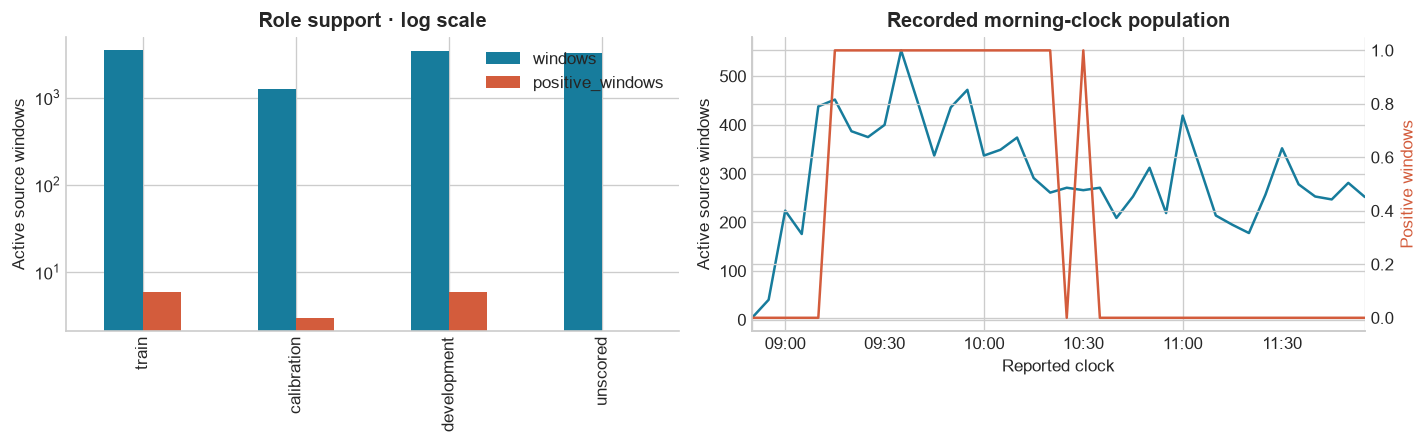

In [5]:
roles = ['train','calibration','development','unscored']
support = data.assign(positive=data.attack_flows.gt(0)).groupby('split').agg(
    windows=('src_ip','size'), positive_windows=('positive','sum'),
    positive_sources=('src_ip',lambda s: data.loc[s.index].loc[data.loc[s.index,'attack_flows'].gt(0),'src_ip'].nunique()),
    unknown_windows=('unknown_flows',lambda s: s.gt(0).sum())).reindex(roles)
support['positive_fraction'] = support.positive_windows / support.windows
display(support)
support.to_csv(RESEARCH / 'sources/current_split_support.csv')
display(pd.read_csv(sql_dir / 'attack_sources.csv'))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
support[['windows','positive_windows']].plot.bar(ax=axes[0], logy=True, color=['#177c9c','#d35c3c'])
axes[0].set(title='Role support · log scale', ylabel='Active source windows', xlabel='')
timeline = data.groupby('window_start').agg(windows=('src_ip','size'),
    positive=('attack_flows',lambda s: s.gt(0).sum()))
timeline.windows.plot(ax=axes[1], color='#177c9c', label='All active windows')
right = axes[1].twinx(); timeline.positive.plot(ax=right, color='#d35c3c', label='Positive windows')
axes[1].set(title='Recorded morning-clock population', ylabel='Active source windows', xlabel='Reported clock')
right.set_ylabel('Positive windows', color='#d35c3c')
finish(fig, 'audit_01_support')

### **Development Support Interpretation**

All positive scoring windows belong to one recorded source and one campaign. Adjacent roles can share that campaign. Six development positives are not six independent attacks. A random row split would not fix this support problem.

### **Visualize Observed Source Coverage**

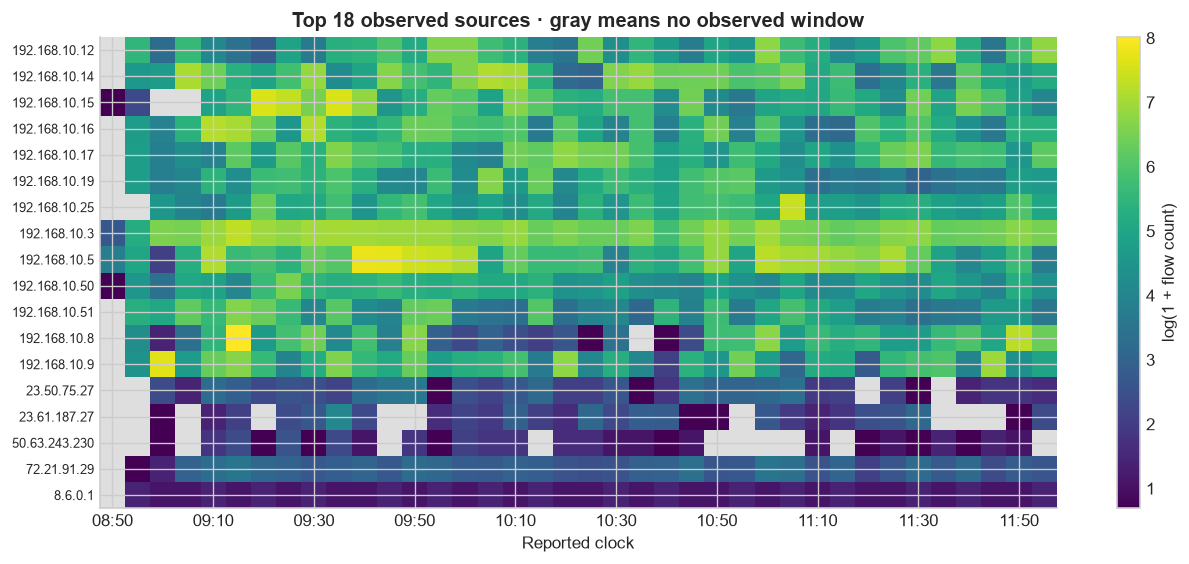

In [6]:
top = data.groupby('src_ip').size().nlargest(18).index
grid = data.loc[data.src_ip.isin(top)].pivot(index='src_ip',columns='window_start',values='flow_count')
palette = plt.get_cmap('viridis').copy(); palette.set_bad('#dedede')
fig, ax = plt.subplots(figsize=(11, 4.8))
image = ax.imshow(np.ma.masked_invalid(np.log1p(grid.to_numpy())), aspect='auto', cmap=palette)
ax.set_yticks(range(len(grid)), grid.index, fontsize=8)
ticks = np.arange(0,len(grid.columns),max(1,len(grid.columns)//8))
ax.set_xticks(ticks, [grid.columns[i].strftime('%H:%M') for i in ticks])
ax.set(title='Top 18 observed sources · gray means no observed window', xlabel='Reported clock')
fig.colorbar(image, ax=ax, label='log(1 + flow count)')
finish(fig, 'audit_02_coverage')

### **Coverage Interpretation**

The heatmap displays the most active observed sources, rather than every possible source. Gray cells indicate that no window was observed. Flow records alone do not establish sensor coverage, so these cells cannot be interpreted as confirmed zero traffic or benign inactivity.

---

# **Part 4: Explore Feature Distributions and Dependence**

**Part 4 Description:** These seven numeric features are available to the classifiers. IPs, time, labels, prior scores and history are excluded from their inputs. Log transforms below are for visualization; model preprocessing is fitted on training data alone in the companion notebook. Correlation is descriptive, not a feature-selection rule tuned on the development set.

### **Describe and Visualize the Seven Model Features**

,count,mean,std,min,50%,90%,99%,max,missing
flow_count,11398.0,1.816161e+01,1.103288e+02,1.0,2.0,8.0,5.710300e+02,3.029000e+03,0
unique_ports,11398.0,3.059396e+00,9.653771e+00,1.0,1.0,6.0,2.200000e+01,7.210000e+02,0
unique_destinations,11398.0,3.050360e+00,1.283981e+01,1.0,1.0,2.0,6.100000e+01,2.780000e+02,0
service_flows,11398.0,7.962800e-01,2.121781e+01,0.0,0.0,0.0,4.000000e+00,6.700000e+02,0
packets,11398.0,7.104328e+02,1.746846e+04,2.0,4.0,20.0,8.638230e+03,9.088550e+05,0
bytes,11398.0,7.225389e+05,2.187217e+07,0.0,0.0,231.0,5.100295e+06,1.154392e+09,0
mean_duration_us,11398.0,1.057376e+06,7.674083e+06,0.0,70.0,36213.4,2.407809e+07,1.197493e+08,0


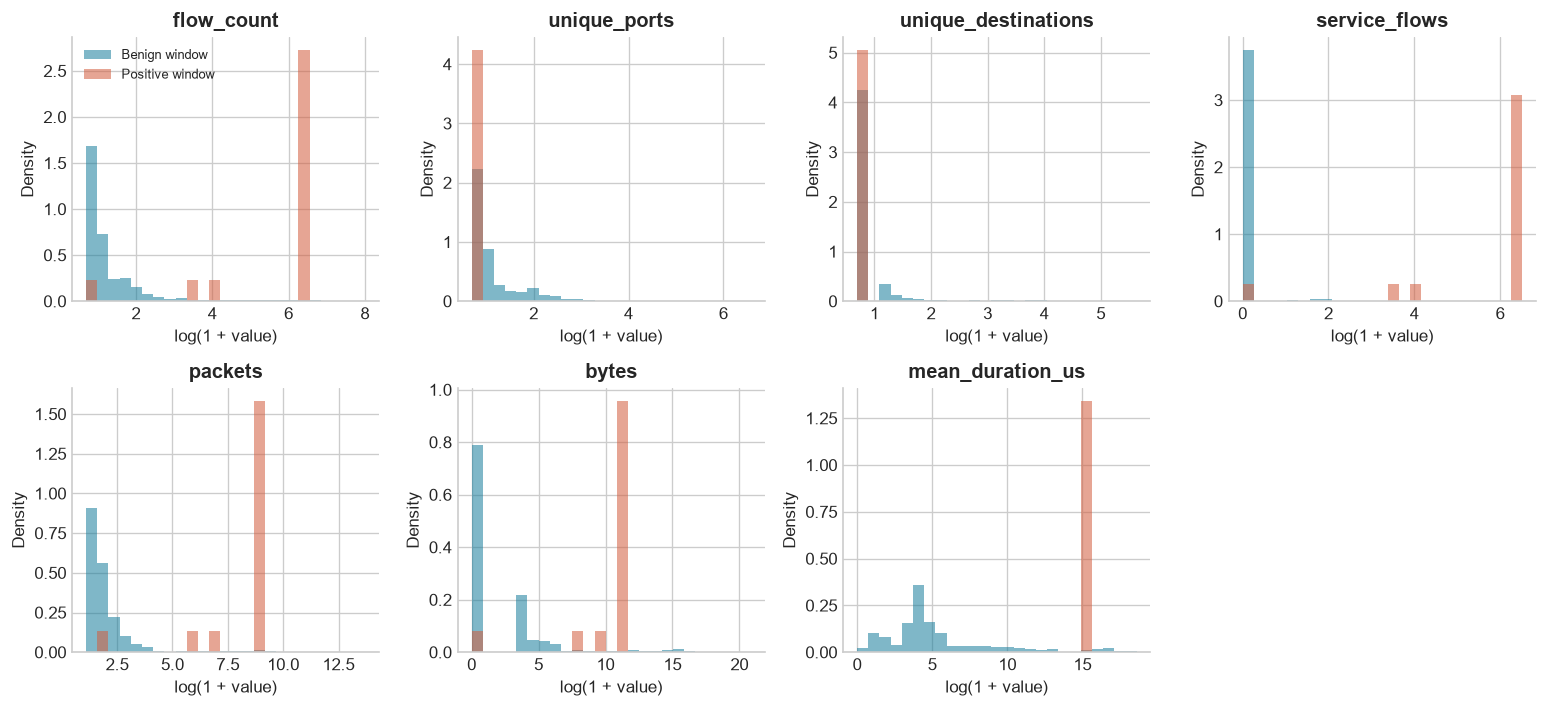

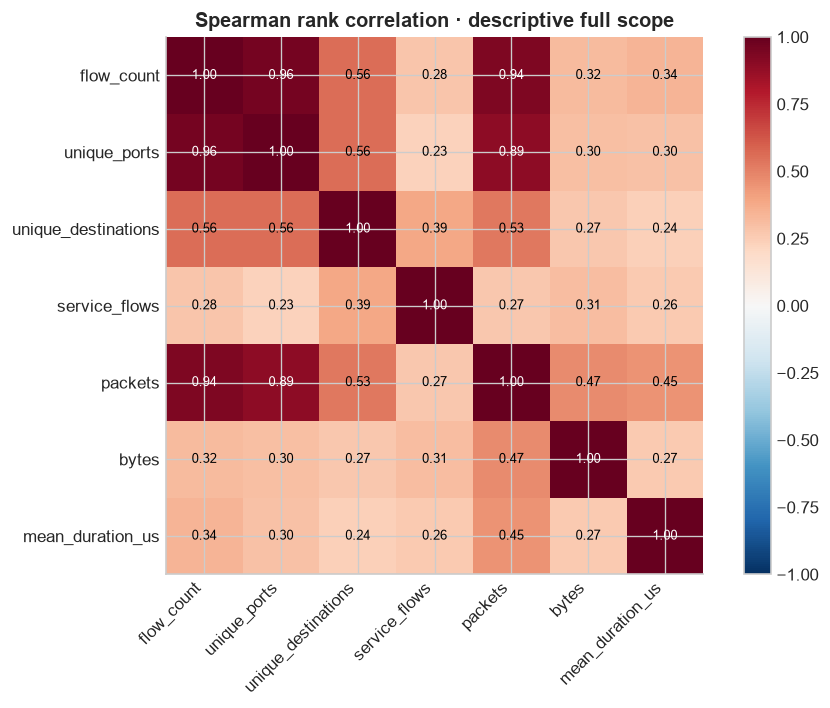

In [7]:
summary = data[FEATURES].describe(percentiles=[.5,.9,.99]).T
summary['missing'] = data[FEATURES].isna().sum()
display(summary)
summary.to_csv(RESEARCH / 'sources/feature_summary.csv')
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for ax, feature in zip(axes.flat, FEATURES):
    bins = np.histogram_bin_edges(np.log1p(data[feature].dropna()), bins=25)
    for attack, color, label in [(False,'#177c9c','Benign window'),(True,'#d35c3c','Positive window')]:
        values = np.log1p(data.loc[data.attack_flows.gt(0).eq(attack),feature].dropna())
        ax.hist(values,bins=bins,alpha=.55,density=True,color=color,label=label)
    ax.set(title=feature, xlabel='log(1 + value)', ylabel='Density')
axes.flat[-1].axis('off'); axes.flat[0].legend(fontsize=8)
finish(fig, 'audit_03_distributions')
corr = data[FEATURES].corr(method='spearman')
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=45, ha='right')
ax.set_yticks(range(len(FEATURES)), FEATURES)
for row in range(len(FEATURES)):
    for col in range(len(FEATURES)):
        ax.text(col,row,f'{corr.iloc[row,col]:.2f}',ha='center',va='center',fontsize=8,
                color='white' if abs(corr.iloc[row,col])>.65 else 'black')
ax.set_title('Spearman rank correlation · descriptive full scope')
fig.colorbar(im,ax=ax)
finish(fig, 'audit_04_correlations')

### **Feature Distribution and Correlation Interpretation**

Read the distributions on the displayed log scale and compare their shapes alongside their small positive support. Related count and size features can describe overlapping behavior; correlation does not establish causation or independent evidence. These descriptive plots do not select model features or transformations using development outcomes.

---

# **Part 5: Compare Candidate Sources and Label Policies**

**Part 5 Description:** The following cell rereads both complete Tuesday members and recomputes the audit. It checks source hashes, duplicate headers/content, missing/nonfinite values, mandatory numeric fields, label support, timestamp parseability/precision, source counts and active windows. Friday is explicitly rejected by this audit function.

The corrected archive is 343,549,013 bytes, SHA-256 `97fdb91d339e2d8cf5627f981b831e5e7e400b981c58181c451a38fd03c48883`. This hash records the retrieved artifact; no independent provider checksum was verified. The author archive inventory contains all weekdays; the analysis opens Tuesday only. An acquisition preview had already read the corrected Friday header and first record. They are excluded from all audit/model results, and Friday is not described as entirely unseen.

[Original source](https://www.unb.ca/cic/datasets/ids-2017.html) · [Corrected release documentation](https://intrusion-detection.distrinet-research.be/CNS2022/CICIDS2017.html) · [Corrected download](https://intrusion-detection.distrinet-research.be/CNS2022/Dataset_Download.html)

Corrected Attempted labels represent distinct behavior and are not silently remapped. The comparison below tests two hypothetical mappings and the default policy of excluding any window containing an unresolved label. Equal positive-window counts under two mappings can still conceal different flow targets or known-negative populations.

[UNSW-NB15's official page](https://research.unsw.edu.au/projects/unsw-nb15-dataset) describes four full CSVs and predefined ML subsets. Its official download was inaccessible (403), so no UNSW missingness, duplicate rate, endpoint/time suitability or class support is claimed here. Its independent capture would be useful for later external validation, after access and a full schema audit. Academic citation requirements apply; commercial permission is separate.

### **Audit the Complete Tuesday Member of Each CIC Release**

In [8]:
from cybershield.source_audit import compare_sources
comparison, audits, hourly, source_windows, decision = compare_sources()
display(comparison.set_index('source').T)
for source, audit in audits.items():
    print(source, 'member SHA-256:', audit['member_sha256'])
    display(pd.Series(audit['label_counts'],name=source).to_frame())
    print('Duplicate headers:',audit['duplicate_header_names'])
    print('Nonfinite rates:',audit['nonfinite_rate_rows_by_column'])
    print('Missing cells:',audit['missing_cells_by_column'])
    print('Time examples:',audit['raw_timestamp_examples'][:3])

source,original,corrected,UNSW-NB15
evidence,full Tuesday records audited,full Tuesday records audited,official documentation only; download HTTP 403
input_rows,445909.0,322078.0,NaN
columns,85.0,91.0,NaN
negative_duration_rows,17.0,0.0,NaN
duplicate_content_rows_excluding_id,4.0,0.0,NaN
temporal_eligible_rows,207006.0,322078.0,NaN
active_windows,11398.0,1514.0,NaN
positive_windows,15.0,29.0,NaN
positive_sources,1.0,1.0,NaN
unknown_windows,0.0,5.0,NaN


original member SHA-256: ae9c88e10c41a8eb1ff454ae98bc513454925097d0b0b57180f94e79de445815


,original
BENIGN,432074
FTP-Patator,7938
SSH-Patator,5897


Duplicate headers: ['Fwd Header Length']
Nonfinite rates: {'Flow Bytes/s': 264, 'Flow Packets/s': 264}
Missing cells: {'Flow Bytes/s': 201}
Time examples: ['4/7/2017 8:54', '4/7/2017 8:55', '4/7/2017 8:53']
corrected member SHA-256: e2a0a5b631dfc6b455cc9f9a88b944110637d70a7f74171473925f76f38b6b0c


,corrected
BENIGN,315106
FTP-Patator,3972
SSH-Patator,2961
SSH-Patator - Attempted,27
FTP-Patator - Attempted,12


Duplicate headers: []
Nonfinite rates: {'Flow Bytes/s': 0, 'Flow Packets/s': 0}
Missing cells: {}
Time examples: ['2017-07-04 11:53:44.398274', '2017-07-04 11:54:12.355218', '2017-07-04 11:54:32.240412']


### **Source Audit Interpretation**

The releases use different extraction/labeling behavior and clock conventions. Record counts, source cardinalities and five-minute window counts therefore need not match. Fewer rows are not evidence of lower coverage. The original temporal percentage is relative to its raw Tuesday input and follows the restricted clock policy; the corrected percentage describes parseable Tuesday rows under its explicit clock. This is an operational source-fitness comparison, not a claim that records align one to one.

### **Visualize Clock Coverage, Defects, and Source Concentration**

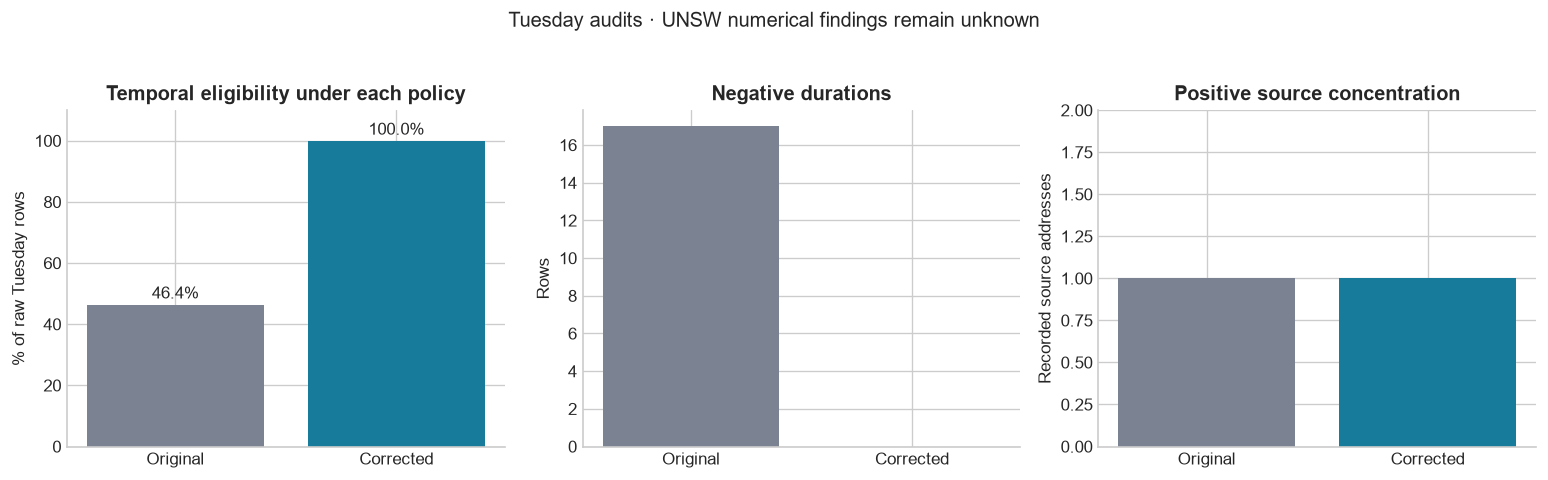

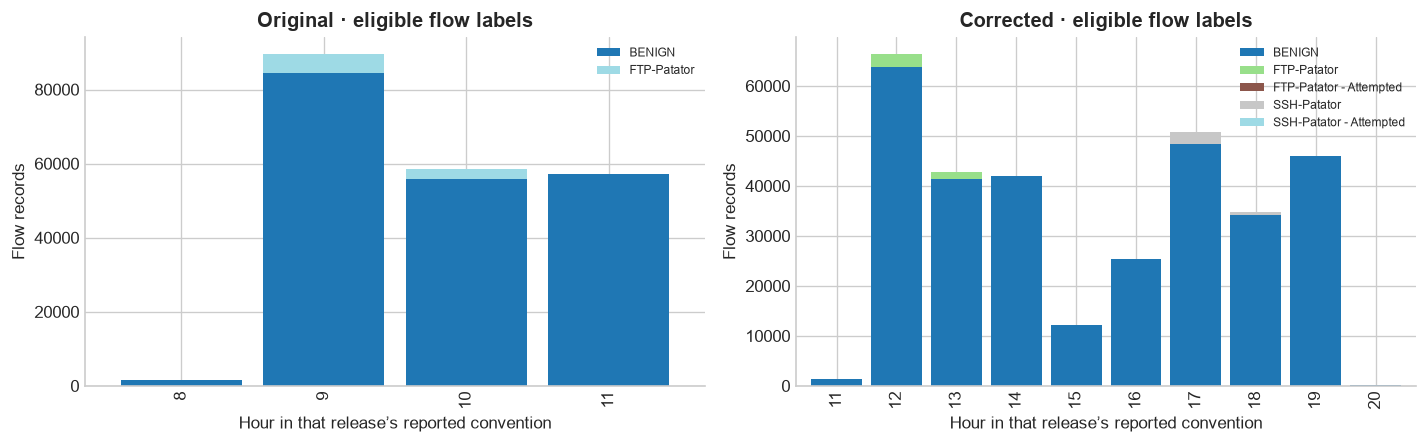

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
names = ['Original','Corrected']; colors = ['#7b8292','#177c9c']
usable = [100*audits[k]['temporal_eligible_rows']/audits[k]['input_rows'] for k in ['original','corrected']]
axes[0].bar(names, usable, color=colors); axes[0].set(ylabel='% of raw Tuesday rows',ylim=(0,110),title='Temporal eligibility under each policy')
for i,v in enumerate(usable): axes[0].text(i,v+2,f'{v:.1f}%',ha='center')
axes[1].bar(names,[audits[k]['negative_duration_rows'] for k in ['original','corrected']],color=colors)
axes[1].set(title='Negative durations',ylabel='Rows')
axes[2].bar(names,[audits[k]['positive_sources'] for k in ['original','corrected']],color=colors)
axes[2].set(title='Positive source concentration',ylabel='Recorded source addresses',ylim=(0,2))
fig.suptitle('Tuesday audits · UNSW numerical findings remain unknown',y=1.04)
finish(fig, 'audit_05_sources')
fig, axes = plt.subplots(1,2,figsize=(12,3.8))
for ax,(source,table) in zip(axes,hourly.items()):
    table.plot.bar(stacked=True,ax=ax,colormap='tab20',width=.85)
    ax.set(title=f'{source.title()} · eligible flow labels',xlabel='Hour in that release’s reported convention',ylabel='Flow records')
    ax.legend(fontsize=7)
finish(fig, 'audit_06_source_clocks')

### **Source Comparison Interpretation**

The corrected release supports explicit subsecond time and broader temporal eligibility under its stated clock convention. Both audited releases still concentrate positive windows in one recorded source. Differences in extraction and labeling mean that row and window counts are not one-to-one retention estimates.

### **Evaluate Attempted-Label Sensitivity and the Third Candidate**

In [10]:
sensitivity = []
for source,w in source_windows.items():
    for policy in ['exclude_unknown_windows','attempted_as_benign','attempted_as_attack']:
        eligible = w.unknown_flows.eq(0) if policy=='exclude_unknown_windows' else pd.Series(True,index=w.index)
        positive = w.attack_flows.gt(0) | (w.attempted_flows.gt(0) if policy=='attempted_as_attack' else False)
        sensitivity.append({'source':source,'policy':policy,'eligible_windows':int(eligible.sum()),
            'positive_windows':int((eligible & positive).sum()),'unresolved_windows':int(w.unknown_flows.gt(0).sum())})
sensitivity = pd.DataFrame(sensitivity)
display(sensitivity)
sensitivity.to_csv(RESEARCH / 'sources/label_sensitivity.csv',index=False)

,source,policy,eligible_windows,positive_windows,unresolved_windows
0,original,exclude_unknown_windows,11398,15,0
1,original,attempted_as_benign,11398,15,0
2,original,attempted_as_attack,11398,15,0
3,corrected,exclude_unknown_windows,1509,24,5
4,corrected,attempted_as_benign,1514,29,5
5,corrected,attempted_as_attack,1514,29,5


### **Label-Policy Interpretation**

Excluding windows with unresolved labels changes the eligible population. Mapping attempted traffic to benign or attack can leave the total number of positive windows unchanged when those windows already contain attack-labeled flows; the underlying targets still differ. UNSW-NB15 remains documentation-only, with numerical quality findings unknown.

---

# **Part 6: Select the Next Source and Record Required Checks**

**Part 6 Description:** Choose the CNS2022 corrected CIC-IDS2017 release for the next ingestion adapter, based on the Tuesday audit: explicit subsecond time, full-day temporal usability, preserved endpoint fields, no observed negative durations or repeated content, and more explicit label provenance. This is a selection for the next development phase, not a validated multi-day or production source. The original remains the running prototype's source until the adapter and target policy are verified.

Both audited releases still concentrate positive traffic in one recorded source. Correction does not create independent attacks, enterprise realism or contemporary traffic. UNSW remains a potential independent validation source with unresolved access and schema evidence. Do not select it—or reject its quality—on unmeasured values.

### **Review the Source Decision**

In [11]:
display(Markdown('**Selected next source:** ' + decision['selected_for_next_data_adapter']))
display(pd.Series(decision['conditions_before_ml_use'], name='Required before model evaluation on the new source').to_frame())
print('Active prototype:',decision['active_prototype_source'])
print('Measured raw rows:',{k:a['input_rows'] for k,a in audits.items()})

**Selected next source:** corrected CIC-IDS2017, CNS2022 release

,Required before model evaluation on the new source
0,Resolve attempted-label target policy and run ...
1,Audit semantic mappings and duration units aga...
2,Create a new UTC-aware ingestion adapter and f...
3,Redesign splits around independent episodes; d...
4,Audit other development days without evaluatin...


Active prototype: original CIC-IDS2017 remains active
Measured raw rows: {'original': 445909, 'corrected': 322078}


### **Decision Interpretation**

The source recommendation is conditional on a verified adapter, an explicit attempted-label policy, and an episode-separated evaluation protocol. It selects the next development source on data fitness, without changing the running application or choosing the source by accuracy.

---

# **Part 7: Conclusion**

The Tuesday audits support the corrected CIC-IDS2017 release for source-by-time SQL analysis. Clearer timestamps, preserved endpoints and more explicit label provenance make it a stronger ingestion source than the original release under the current restricted morning-clock policy.

This is a source-fitness decision, not evidence of better detection accuracy. The original and corrected releases describe the same capture, so they do not provide independent validation. Attempted or unresolved labels need an explicit policy, and repeated windows from one source or campaign must not be treated as independent attacks.

The next step is to verify adapter mappings, reconcile accepted and excluded records, and establish chronological, episode-aware evaluation support before comparing models. UNSW-NB15 remains a documentation-only candidate until its files and schema can be audited directly.

---
